# Effetto della penalità da import sulla fitness dei paesi

La fitness estesa con import sottrae al termine "lordo" la penalità $S_c$ per gli input importati:
$$F_c = \sum_p M_{cp} Q_p - S_c .$$
L'obiettivo è penalizzare gli **assemblatori**: paesi che esportano prodotti complessi importandone gli input.
Qui si misura:

1. **quota di penalità** $S_c / \sum_p M_{cp} Q_p$: quanta parte della fitness lorda viene tolta;
2. **effetto netto**: variazione del percentile di rango del paese rispetto alla stessa fitness estesa **senza** import
   (stessa C, stesso $a$);
3. **validazione indipendente**: confronto con la quota di valore aggiunto estero nell'export (OECD TiVA,
   `EXGR_FVA / EXGR`, *backward participation* nelle catene globali del valore), la misura standard di quanto un paese
   assembla input importati. Se il filtro funziona, i paesi con più valore aggiunto estero devono essere i più penalizzati.

Figure in `plots/econometria/effetto_import/`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = next(p for p in [Path().resolve(), *Path().resolve().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
import matplotlib.pyplot as plt
from src.plotting import (set_style, figsize, save_fig, two_part_legend, common_ylim,
                          SINGLE, HALF, PALETTE, RES_MARKER, SEQ_CMAP, SYMBOLS)

set_style()

from src.algorithms import compute_alpha, compute_extended_fitness_no_imports, compute_extended_eci_no_imports
from src.algorithms_with_imports import compute_extended_fitness_with_imports, compute_extended_eci_with_imports

## Configurazione

In [2]:
ALGO = "ext_fitness"                 # "ext_fitness" | "ext_eci"
RES = 4
A = 1.0
TENSOR_WINDOW = 3
YEARS = [2002, 2007, 2012, 2017, 2022]   # TiVA arriva al 2022
YEAR_PLOT = 2012
MIN_POP = 1.0                            # milioni: esclude i micro-stati dalle classifiche
N_LABEL = 10                             # paesi etichettati nei grafici

ALGOS = {"ext_fitness": (compute_extended_fitness_with_imports, compute_extended_fitness_no_imports, "Extended Fitness"),
         "ext_eci":     (compute_extended_eci_with_imports,     compute_extended_eci_no_imports,     "Extended ECI")}
DATA = ROOT / "data" / "HS02_all_years" / f"{RES}_digits" / "alligned" / "binarized"
SAVE_FIGS = True
FIG_DIR = ROOT / "plots" / "econometria" / "effetto_import" / ALGO

## Fitness con e senza import

In [3]:
iso3 = pd.read_csv(ROOT / "data" / "raw" / "BACI" / "country_codes_V202601.csv").set_index("country_code")["country_iso3"]
C = pd.read_parquet(DATA / "C" / f"C_{RES}_digits_HS02.parquet")
alpha = A * compute_alpha(C)
with_imp, no_imp, ALGO_LABEL = ALGOS[ALGO]

def pct(x):
    return x.rank(pct=True)

rows = []
for year in YEARS:
    Me = pd.read_parquet(DATA / "Mcp_export" / f"Mcp_export_alligned_Y{year}.parquet")
    Mi = pd.read_parquet(DATA / "Mcp_import" / f"Mcp_import_alligned_Y{year}.parquet")
    Q, F, CQ, Delta, S = with_imp(Me, Mi, C.T, alpha=alpha, tensor_window=TENSOR_WINDOW, max_iter=5000,
                                  tol=1e-6, track_convergence=False, save_delta=False, delta_window=None)
    Q0, F0, CQ0, Delta0 = no_imp(Me, C.T, alpha=alpha, max_iter=5000, tol=1e-6, track_convergence=False)
    gross = pd.Series(Me.values @ Q.reindex(Me.columns).values, index=Me.index)
    rows.append(pd.DataFrame({"year": year, "iso3": Me.index.map(iso3), "F_import": F, "F_senza": F0,
                              "S": S, "lordo": gross}))
df = pd.concat(rows, ignore_index=True)
df["quota_penalita"] = df["S"] / df["lordo"]
df["d_percentile"] = df.groupby("year")["F_import"].transform(pct) - df.groupby("year")["F_senza"].transform(pct)
df["log_rapporto"] = np.log(df["F_import"] / df["F_senza"])

C:\Users\vitto\Desktop\CSH RESEARCH\src\algorithms.py:251: RuntimeWarning: divide by zero encountered in divide
  Delta = 1.0 / (M.T @ (1.0 / F_old))
C:\Users\vitto\Desktop\CSH RESEARCH\src\algorithms.py:251: RuntimeWarning: divide by zero encountered in divide
  Delta = 1.0 / (M.T @ (1.0 / F_old))


## Dati esterni: popolazione (PWT) e valore aggiunto estero nell'export (TiVA)

In [4]:
pwt = pd.read_excel(ROOT / "results" / "econometria" / "raw" / "pwt110.xlsx", sheet_name="Data", usecols=["countrycode", "year", "pop"])
tiva = pd.read_csv(ROOT / "data" / "raw" / "TiVa" / "tiva_exgr_fva_totale.csv")
tiva = tiva.pivot_table(index=["REF_AREA", "TIME_PERIOD"], columns="MEASURE", values="OBS_VALUE")
tiva["quota_va_estero"] = tiva["EXGR_FVA"] / tiva["EXGR"]

df = df.merge(pwt.rename(columns={"countrycode": "iso3"}), on=["iso3", "year"], how="left")
df = df.merge(tiva["quota_va_estero"].rename_axis(["iso3", "year"]).reset_index(), on=["iso3", "year"], how="left")
big = df[df["pop"] >= MIN_POP]
print(f"paesi con pop >= {MIN_POP} M: {big.groupby('year').size().to_dict()}; con dato TiVA: {big.dropna(subset=['quota_va_estero']).groupby('year').size().to_dict()}")
d = big[big.year == YEAR_PLOT].set_index("iso3")

paesi con pop >= 1.0 M: {2002: 144, 2007: 148, 2012: 149, 2017: 150, 2022: 150}; con dato TiVA: {2002: 73, 2007: 73, 2012: 73, 2017: 73, 2022: 73}


## 1. Chi viene penalizzato di più

In [5]:
cols = ["quota_penalita", "d_percentile", "log_rapporto", "quota_va_estero"]
print("piu' penalizzati (variazione di percentile)")
display(d.sort_values("d_percentile")[cols].head(15).round(3))
print("piu' favoriti")
display(d.sort_values("d_percentile", ascending=False)[cols].head(10).round(3))

piu' penalizzati (variazione di percentile)


,quota_penalita,d_percentile,log_rapporto,quota_va_estero
iso3,,,,
BGD,0.378,-0.097,-0.330,0.159
IDN,0.300,-0.075,-0.182,0.131
PAK,0.319,-0.066,-0.223,0.101
VNM,0.371,-0.062,-0.293,0.350
KHM,0.249,-0.062,-0.126,0.284
MEX,0.288,-0.062,-0.157,0.291
COL,0.215,-0.053,-0.067,0.083
LKA,0.272,-0.053,-0.153,NaN
TUR,0.342,-0.049,-0.245,0.230


piu' favoriti


,quota_penalita,d_percentile,log_rapporto,quota_va_estero
iso3,,,,
SGP,0.089,0.049,0.105,0.465
PAN,0.030,0.040,0.153,NaN
LBN,0.091,0.040,0.089,NaN
PHL,0.129,0.031,0.045,0.196
PSE,0.059,0.031,0.124,NaN
NLD,0.102,0.027,0.081,0.292
GRC,0.081,0.027,0.097,0.316
CHE,0.099,0.022,0.087,0.213
HKG,0.109,0.022,0.070,0.230


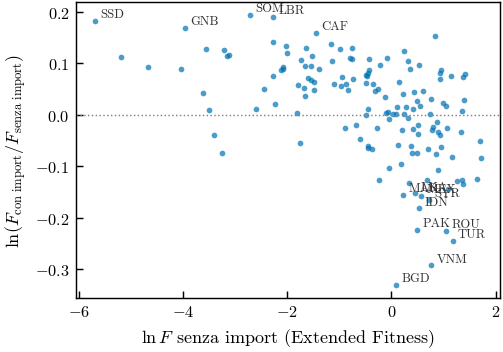

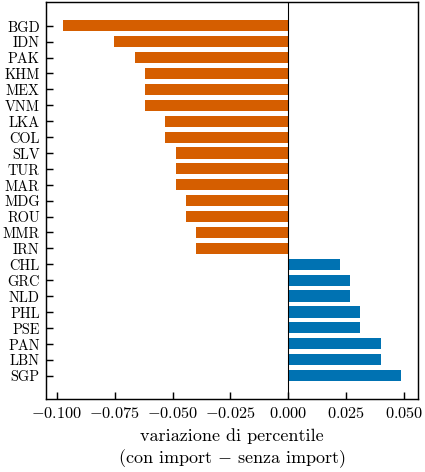

In [6]:
def label_points(ax, sub, xcol, ycol, fontsize=7):
    for c, r_ in sub.iterrows():
        ax.annotate(c, (r_[xcol], r_[ycol]), xytext=(3, 2), textcoords="offset points", fontsize=fontsize, color="0.2")

# effetto della penalita' in funzione della fitness senza import (0 = nessun effetto)
fig, ax = plt.subplots(figsize=figsize(*SINGLE))
tmp = d.assign(x=np.log(d["F_senza"]), y=d["log_rapporto"])
ax.scatter(tmp["x"], tmp["y"], s=10, color=PALETTE[4], alpha=0.7, lw=0)
ax.axhline(0, color="0.5", lw=0.8, ls=":")
label_points(ax, pd.concat([tmp.nsmallest(N_LABEL, "log_rapporto"), tmp.nlargest(5, "log_rapporto")]), "x", "y")
ax.set_xlabel(rf"$\ln F$ senza import ({ALGO_LABEL})")
ax.set_ylabel(r"$\ln (F_{\mathrm{con\ import}} / F_{\mathrm{senza\ import}})$")
fig.tight_layout()
if SAVE_FIGS:
    save_fig(fig, FIG_DIR / f"fitness_con_senza_import_{YEAR_PLOT}")
plt.show()

# classifica per variazione di percentile
top = pd.concat([d.nsmallest(15, "d_percentile"), d.nlargest(8, "d_percentile").iloc[::-1]])
fig, ax = plt.subplots(figsize=figsize(0.6, 1.1))
colors = [PALETTE[6] if v < 0 else PALETTE[4] for v in top["d_percentile"]]
ax.barh(range(len(top)), top["d_percentile"], color=colors, height=0.7)
ax.set_yticks(range(len(top))); ax.set_yticklabels(top.index, fontsize=8)
ax.invert_yaxis()
ax.axvline(0, color="k", lw=0.6)
ax.set_xlabel("variazione di percentile\n(con import $-$ senza import)")
fig.tight_layout()
if SAVE_FIGS:
    save_fig(fig, FIG_DIR / f"classifica_penalizzati_{YEAR_PLOT}")
plt.show()

## 2. Validazione: la penalità colpisce chi assembla input esteri?

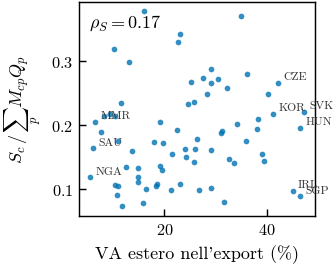

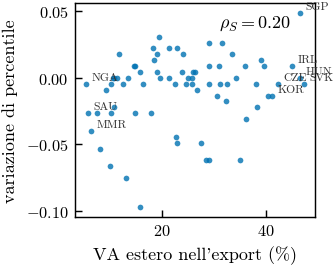

In [7]:
v = d.dropna(subset=["quota_va_estero"])
for ycol, ylabel, fname in (("quota_penalita", r"$S_c \,/\, \sum_p M_{cp} Q_p$", "va_estero_vs_quota_penalita"),
                            ("d_percentile", "variazione di percentile", "va_estero_vs_variazione_percentile")):
    fig, ax = plt.subplots(figsize=figsize(*HALF))
    ax.scatter(100 * v["quota_va_estero"], v[ycol], s=10, color=PALETTE[4], alpha=0.8, lw=0)
    rho = v[["quota_va_estero", ycol]].corr(method="spearman").iloc[0, 1]
    ext = pd.concat([v.nlargest(6, "quota_va_estero"), v.nsmallest(3, "quota_va_estero")])
    label_points(ax, ext.assign(xx=100 * ext["quota_va_estero"]), "xx", ycol, fontsize=6.5)
    ax.set_xlabel("VA estero nell'export (%)")
    ax.set_ylabel(ylabel)
    ax.text(0.04 if ycol == "quota_penalita" else 0.60, 0.95, rf"$\rho_S = {rho:.2f}$", transform=ax.transAxes, va="top")
    fig.tight_layout()
    if SAVE_FIGS:
        save_fig(fig, FIG_DIR / f"{fname}_{YEAR_PLOT}")
    plt.show()

## 3. Stabilità nel tempo e ruolo della dimensione del paese

La quota di valore aggiunto estero dipende fortemente dalla dimensione: le piccole economie aperte ne hanno molto
per costruzione. Oltre alla correlazione semplice si riporta quindi la correlazione parziale di Spearman
**a parità di popolazione** (log).

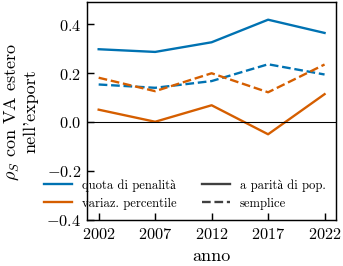

,n,"rho(VA estero, quota penalita')","rho(VA estero, quota penalita' | pop)","rho(VA estero, variazione percentile)","rho(VA estero, variazione percentile | pop)"
year,,,,,
2002,73,0.152,0.296,0.179,0.049
2007,73,0.138,0.285,0.124,-0.001
2012,73,0.166,0.324,0.198,0.067
2017,73,0.234,0.416,0.120,-0.052
2022,73,0.193,0.362,0.233,0.112


In [8]:
def partial_spearman(d, x, y, z):
    R = d[[x, y, z]].dropna().corr(method="spearman")
    rxy, rxz, ryz = R.loc[x, y], R.loc[x, z], R.loc[y, z]
    return (rxy - rxz * ryz) / np.sqrt((1 - rxz ** 2) * (1 - ryz ** 2))

rows = []
for year, g in big.dropna(subset=["quota_va_estero"]).assign(lnpop=lambda t: np.log(t["pop"])).groupby("year"):
    rows.append({"year": year, "n": len(g),
                 "rho(VA estero, quota penalita')": g[["quota_va_estero", "quota_penalita"]].corr(method="spearman").iloc[0, 1],
                 "rho(VA estero, quota penalita' | pop)": partial_spearman(g, "quota_va_estero", "quota_penalita", "lnpop"),
                 "rho(VA estero, variazione percentile)": g[["quota_va_estero", "d_percentile"]].corr(method="spearman").iloc[0, 1],
                 "rho(VA estero, variazione percentile | pop)": partial_spearman(g, "quota_va_estero", "d_percentile", "lnpop")})
trend = pd.DataFrame(rows).set_index("year")

fig, ax = plt.subplots(figsize=figsize(*HALF))
ax.plot(trend.index, trend.iloc[:, 1], color=PALETTE[4], ls="--")
ax.plot(trend.index, trend.iloc[:, 2], color=PALETTE[4])
ax.plot(trend.index, trend.iloc[:, 3], color=PALETTE[6], ls="--")
ax.plot(trend.index, trend.iloc[:, 4], color=PALETTE[6])
ax.set_xticks(trend.index)
ax.axhline(0, color="k", lw=0.6)
ax.set_xlabel("anno"); ax.set_ylabel(r"$\rho_S$ con VA estero" + "\n" + "nell'export")
lo, hi = ax.get_ylim(); ax.set_ylim(min(lo, -0.1) - 0.3, hi + 0.05)
two_part_legend(ax, [("quota di penalità", PALETTE[4]), ("variaz. percentile", PALETTE[6])],
                [("a parità di pop.", "-", True), ("semplice", "--", False)], loc="lower right", ncol=2, fontsize=7)
fig.tight_layout()
if SAVE_FIGS:
    save_fig(fig, FIG_DIR / "correlazione_va_estero_per_anno")
plt.show()
trend.round(3)